# OHLCV Data Visualization Demo

This notebook demonstrates how to visualize OHLCV (Open, High, Low, Close, Volume) data and technical indicators using the tdata package. We'll cover:
1. Fetching market data
2. Calculating technical indicators
3. Visualizing various charts including:
   - Candlestick patterns with volume
   - Moving Averages (SMA)
   - Relative Strength Index (RSI)
   - MACD (Moving Average Convergence Divergence)
   - Bollinger Bands
   - ADX (Average Directional Index)
   - Stochastic Oscillator
   - On-Balance Volume (OBV)

In [2]:
import pandas as pd
import numpy as np
import mplfinance as mpf
from datetime import datetime, timedelta
import pandas_ta as ta
import os

# Import tdata package functionality
from packages.tdata.ingestion import get_rts_data, extract_tickers, get_figis, fetch_ohlcv_data
from packages.tdata.processing import calculate_indicators, process_file_with_indicators

# Loading Market Data

In this notebook, we'll demonstrate loading market data using the updated tdata package. The package now automatically handles:
1. Date conversion to pandas datetime format
2. Setting the original 'date' column as the index
3. Preserving datetime information in 'date_time' column for calculations
4. Basic data preprocessing and validation

The data will be structured with:
- DateTime index (from 'date' column) for time series operations
- `date_time` column preserved for calculations and indicators
- All standard OHLCV columns

This means you no longer need to manually convert dates or set index - these operations are handled internally by the `fetch_ohlcv_data` function.

In [3]:
# Load environment variables from .env file
TOKEN = os.getenv("TINKOFF_TOKEN")

# Set the date range for data retrieval
end_date = pd.Timestamp("2024-12-31T12:00:00Z")
start_date = end_date - timedelta(days=30)

# Define the candle interval
interval = "15min"  # Options: 1min, 5min, 15min, 1hour, 1day, etc.

# Get tickers and their FIGIs
tickers = extract_tickers()
ticker_figis = get_figis(tickers, TOKEN)

# Fetch OHLCV data and calculate indicators
df = fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN)
# Save df as test CSV file
df.to_csv("./data/data/test_ohlcv_data_15min.csv")

KeyboardInterrupt: 

In [2]:
# Read df with index and process it with indicators
df = pd.read_csv("./data/data/test_ohlcv_data_15min.csv", index_col='date')

# Calculate indicators and remove rows with NaN values
df = calculate_indicators(df, drop_na_rows=True, min_coverage=0.9)

# Print data info to verify
print("\nDataset info after cleaning:")
print(f"Total rows: {len(df)}")
print("\nSample of first few rows to verify indicators:")
print(df[['tic', 'close', 'rsi', 'macd_line', 'bb_middle']].head())


Dataset info after cleaning:
Total rows: 73400

Sample of first few rows to verify indicators:
                            tic   close        rsi  macd_line  bb_middle
date                                                                    
2024-12-02 20:00:00+00:00  AFKS  12.506  47.523705  -0.013550   12.49775
2024-12-02 20:15:00+00:00  AFKS  12.510  48.613783  -0.011783   12.49985
2024-12-02 20:30:00+00:00  AFKS  12.528  53.313610  -0.008829   12.50180
2024-12-02 20:45:00+00:00  AFKS  12.522  51.618855  -0.006892   12.50345
2024-12-03 04:00:00+00:00  AFKS  12.530  53.730808  -0.004658   12.50405


In [5]:
df.to_csv("./data/data/test_ohlcv_data_15min_indicators.csv")
df

,figi,open,high,low,close,volume,tic,day,rsi,macd_line,...,bb_lower,bb_middle,bb_upper,vwap,adx,adx_positive,adx_negative,stoch_k,stoch_d,obv
date,,,,,,,,,,,,,,,,,,,,,
2024-12-02 20:00:00+00:00,BBG004S68614,12.496,12.521,12.492,12.506,3786,AFKS,0,47.523705,-0.013550,...,12.471998,12.49775,12.523502,12.669565,10.609421,22.272341,16.297283,60.052910,55.707121,45611.0
2024-12-02 20:15:00+00:00,BBG004S68614,12.505,12.520,12.503,12.510,1177,AFKS,0,48.613783,-0.011783,...,12.477523,12.49985,12.522177,12.669418,10.958703,21.465494,15.706891,69.841270,60.931989,46788.0
2024-12-02 20:30:00+00:00,BBG004S68614,12.510,12.534,12.507,12.528,3653,AFKS,0,53.313610,-0.008829,...,12.476936,12.50180,12.526664,12.668999,11.763885,23.238437,14.790446,81.424281,70.439487,50441.0
2024-12-02 20:45:00+00:00,BBG004S68614,12.529,12.535,12.522,12.522,818,AFKS,0,51.618855,-0.006892,...,12.477834,12.50345,12.529066,12.668907,12.545232,22.781918,14.356119,84.641213,78.635588,49623.0
2024-12-03 04:00:00+00:00,BBG004S68614,12.491,12.535,12.469,12.530,458,AFKS,1,53.730808,-0.004658,...,12.476602,12.50405,12.531498,12.668851,12.286589,19.630208,23.479387,89.031957,85.032484,50081.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-28 19:00:00+00:00,TCS00A107T19,3909.000,3913.500,3908.500,3911.000,1430,YDEX,5,55.357297,5.112636,...,3882.459088,3905.70000,3928.940912,3521.138314,26.249646,32.485720,18.632846,52.115763,51.188346,2859597.0
2024-12-28 19:15:00+00:00,TCS00A107T19,3911.500,3916.000,3911.500,3916.000,1208,YDEX,5,58.544659,5.248528,...,3884.325014,3906.95000,3929.574986,3521.156688,26.542245,33.282353,17.785336,57.622115,53.487505,2860805.0
2024-12-28 19:30:00+00:00,TCS00A107T19,3916.000,3916.500,3914.000,3916.500,3025,YDEX,5,58.860974,5.335070,...,3886.279167,3908.17500,3930.070833,3521.202826,26.861213,32.964821,17.360155,57.585269,55.774382,2863830.0


## Visualizing Technical Indicators

Let's create various plots to analyze the price action and technical indicators:

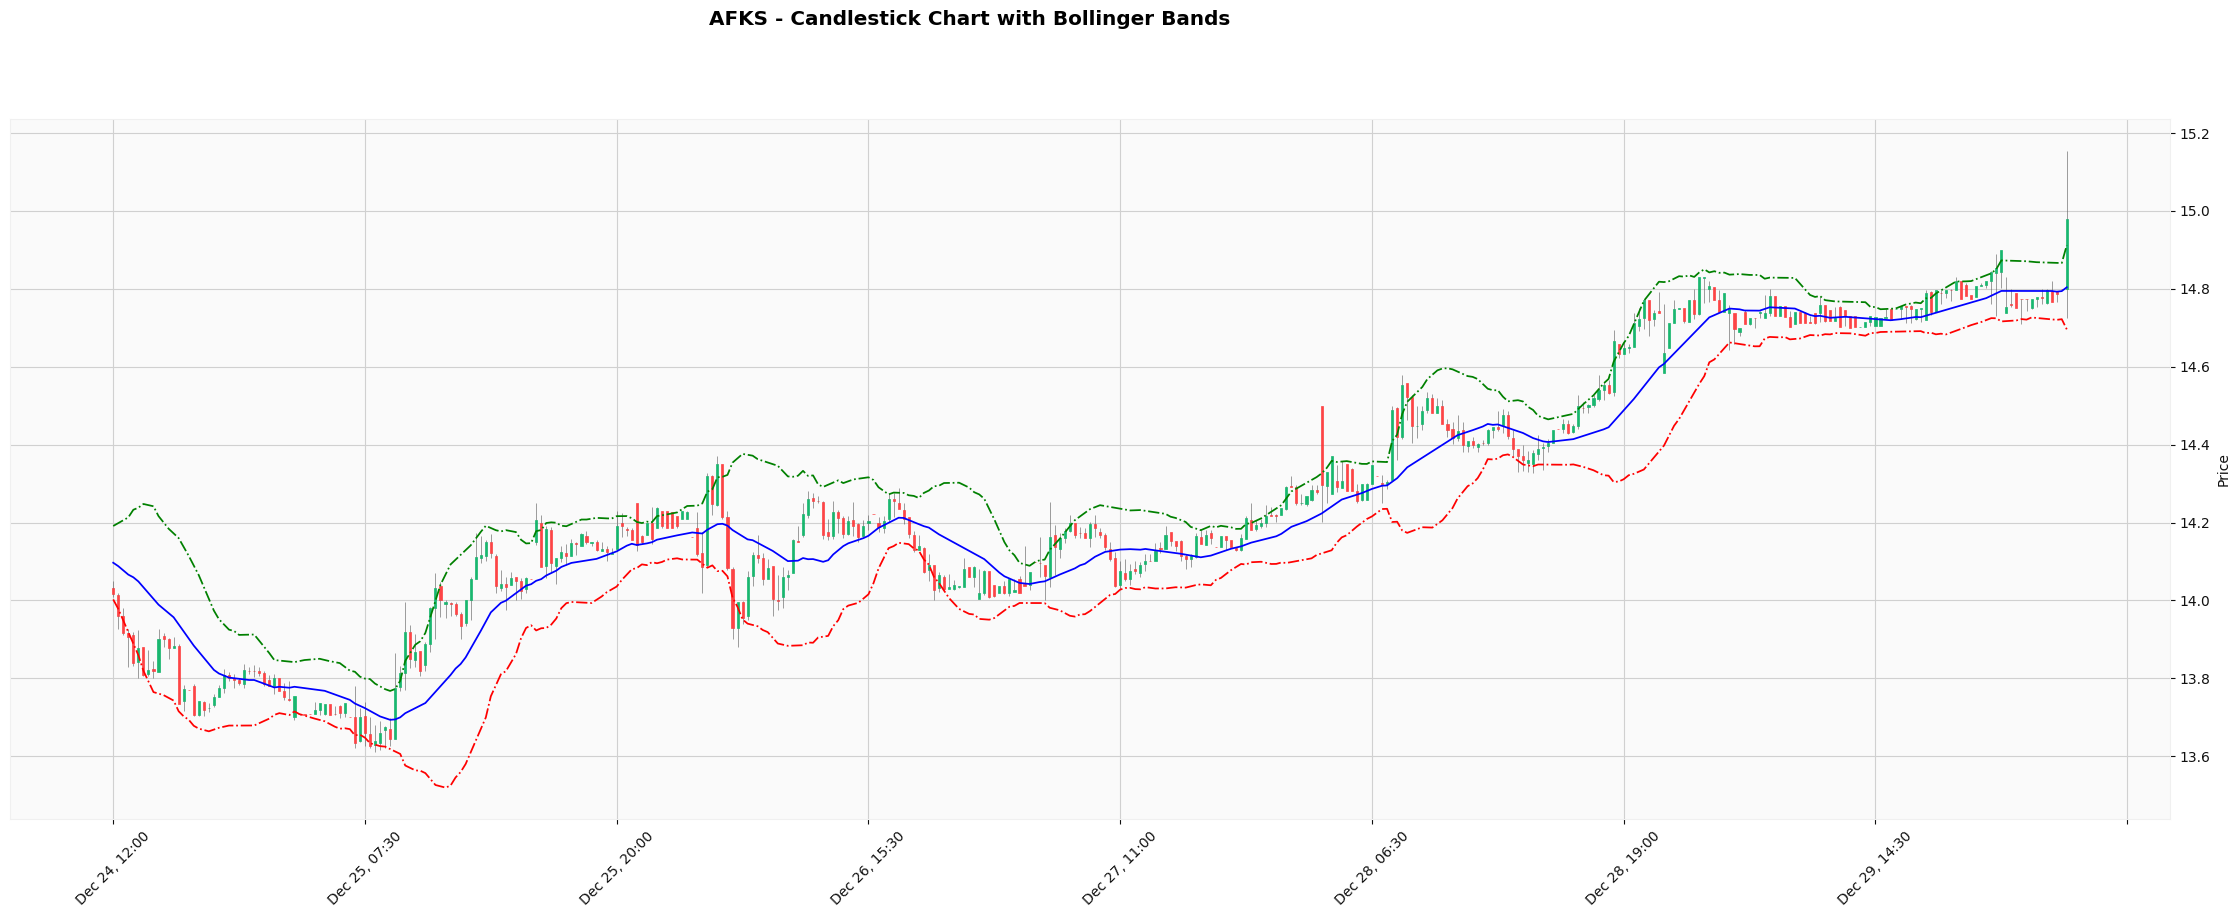

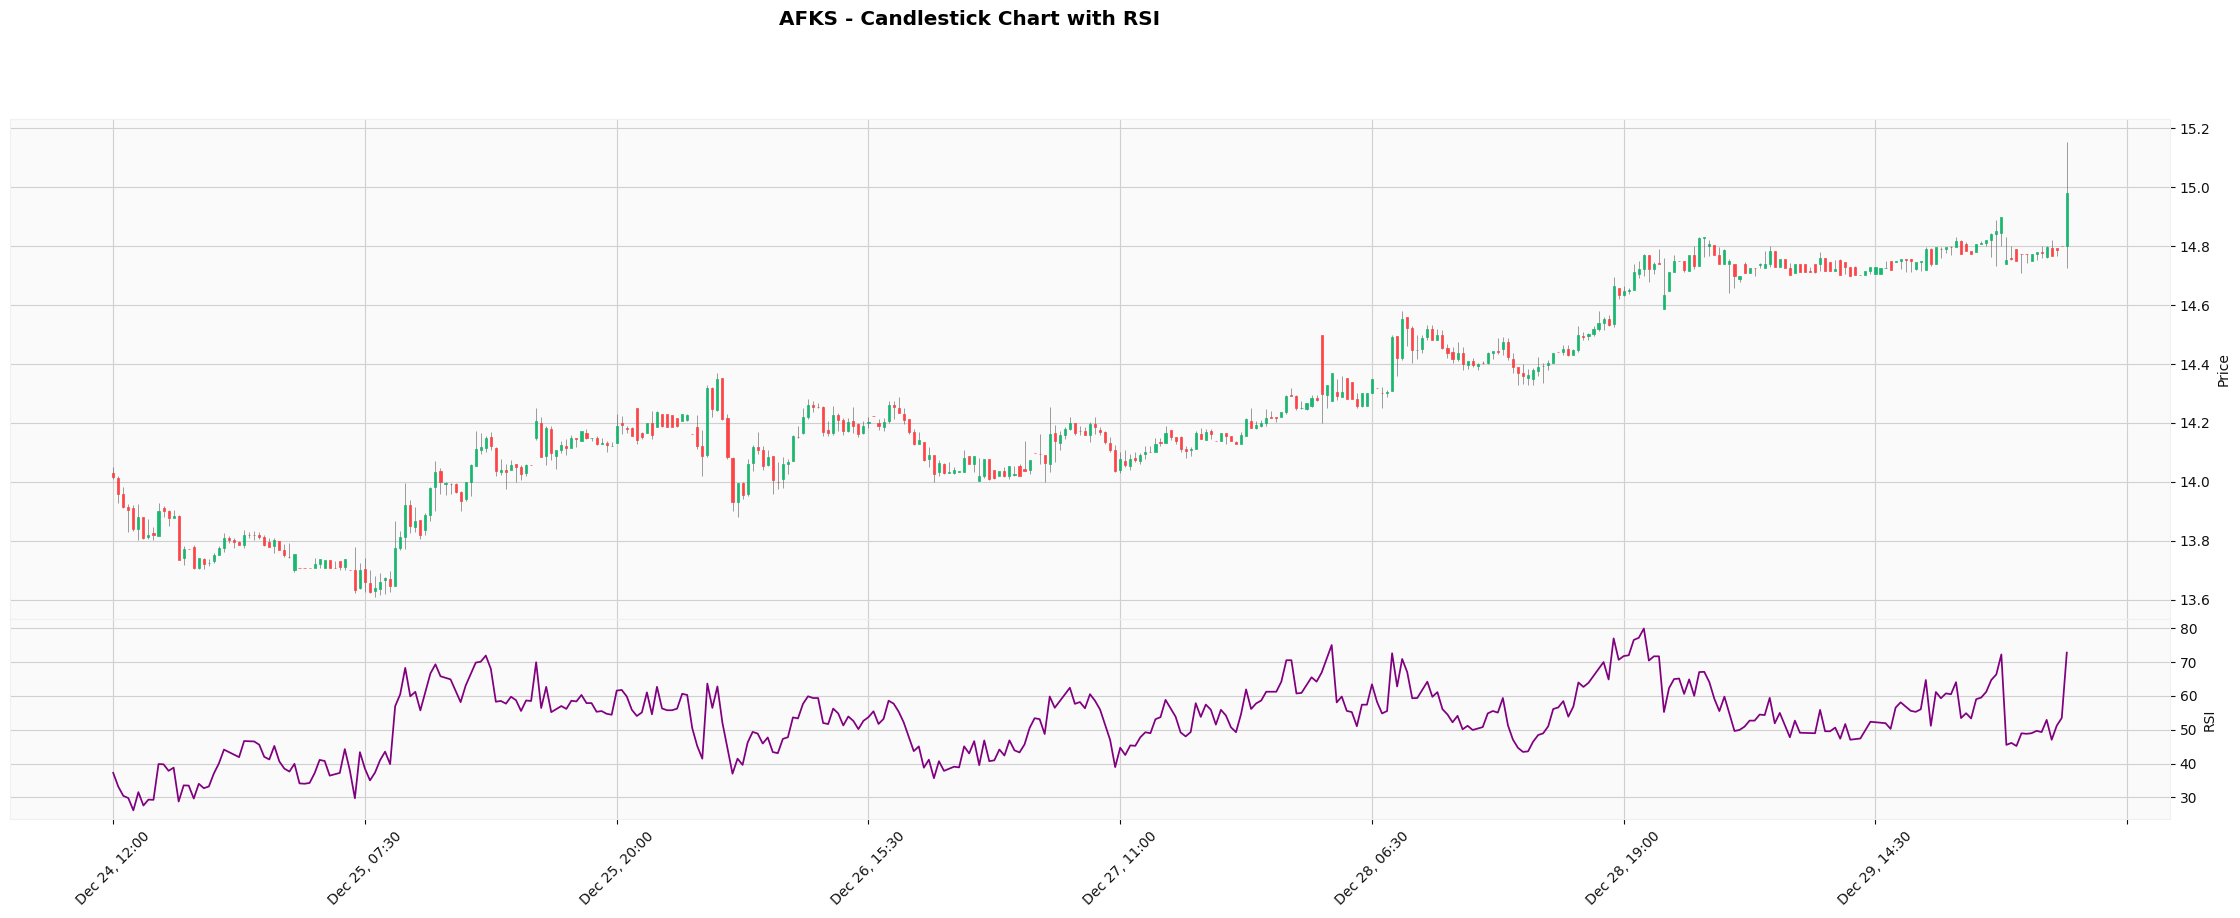

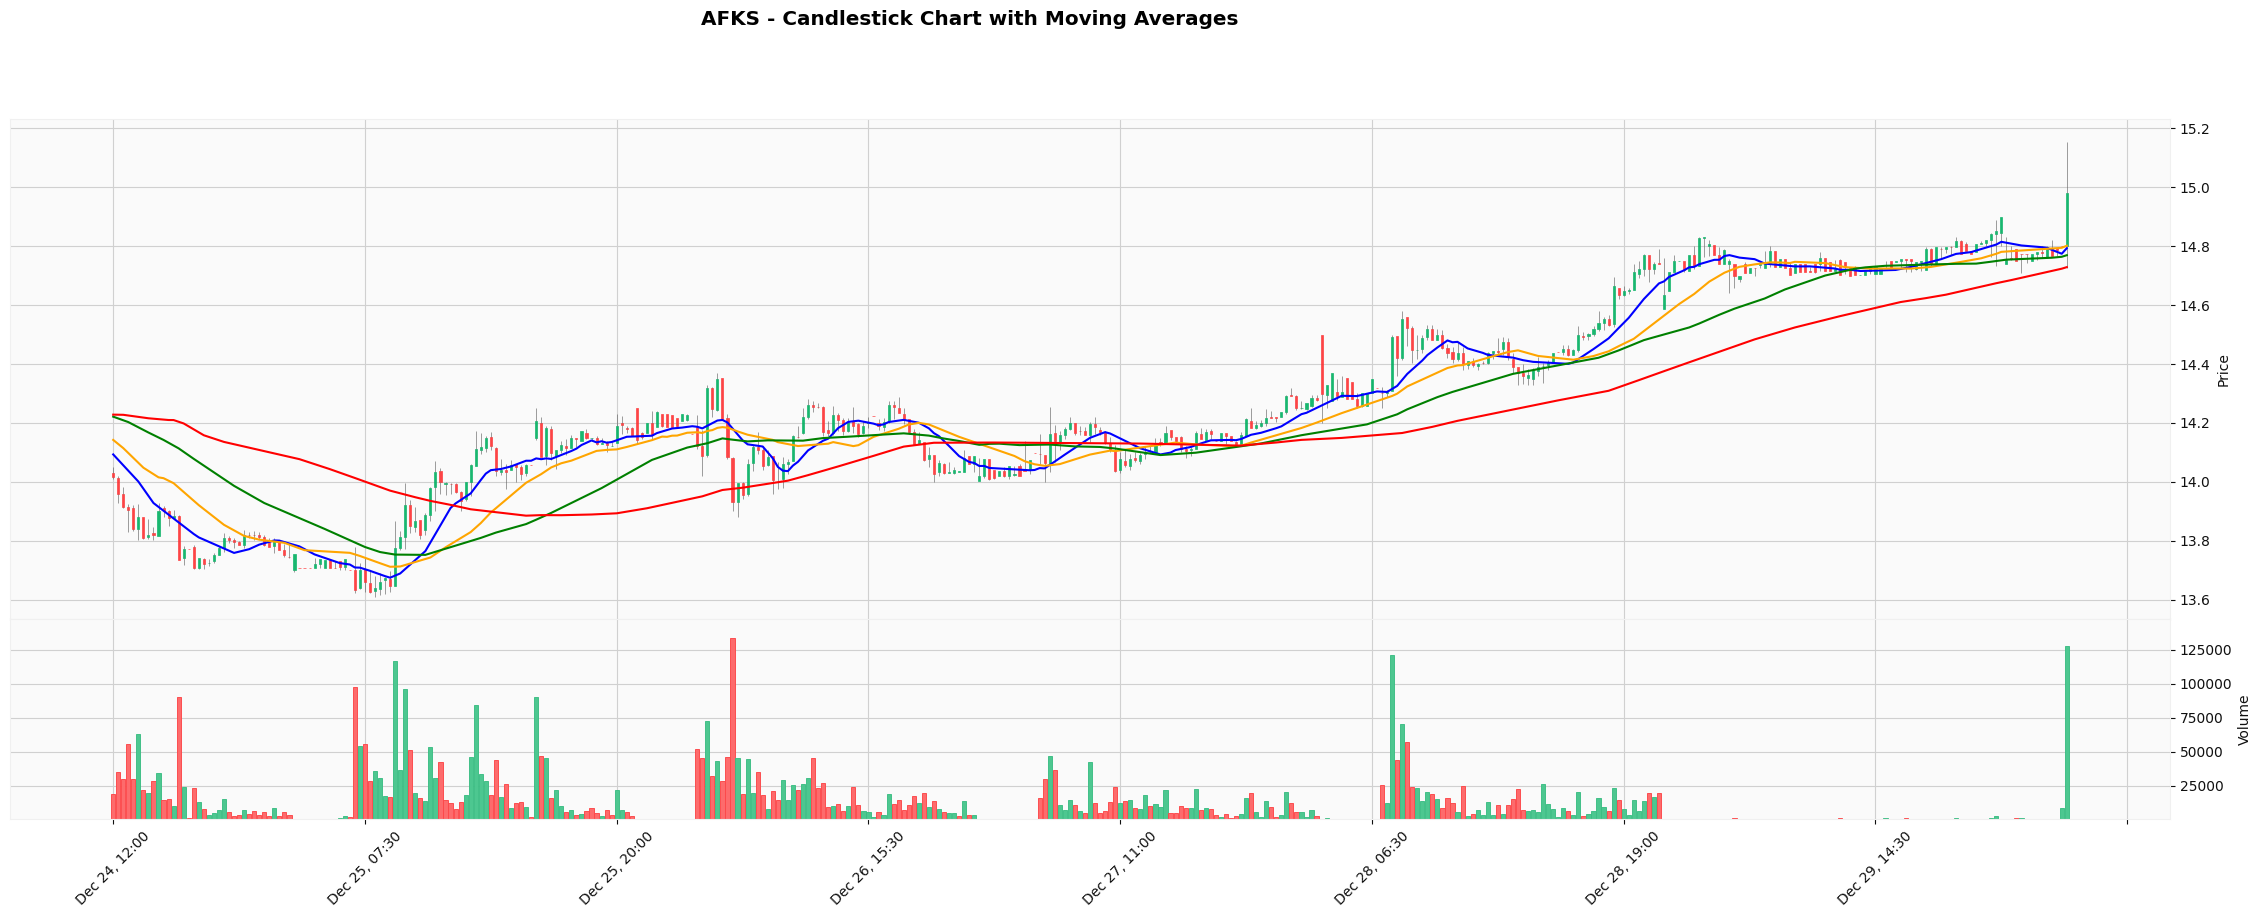

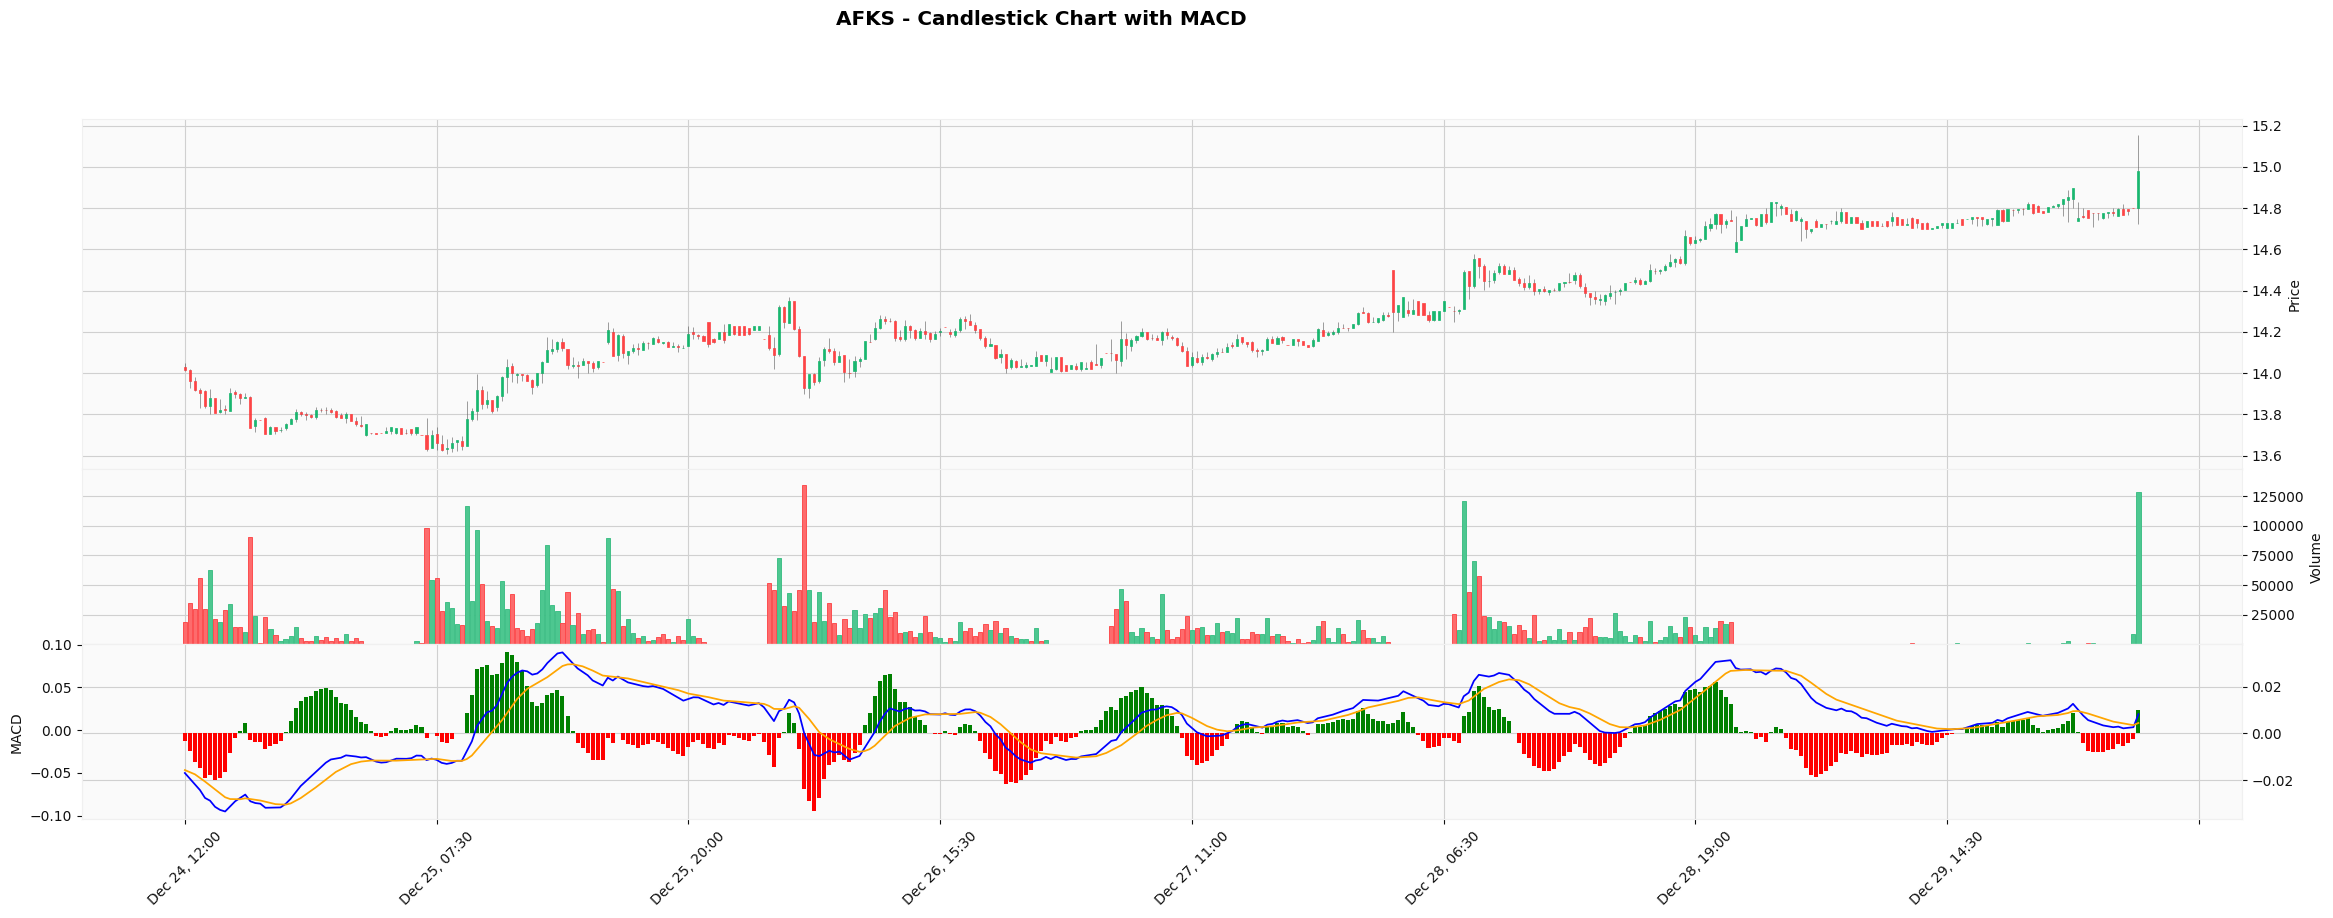

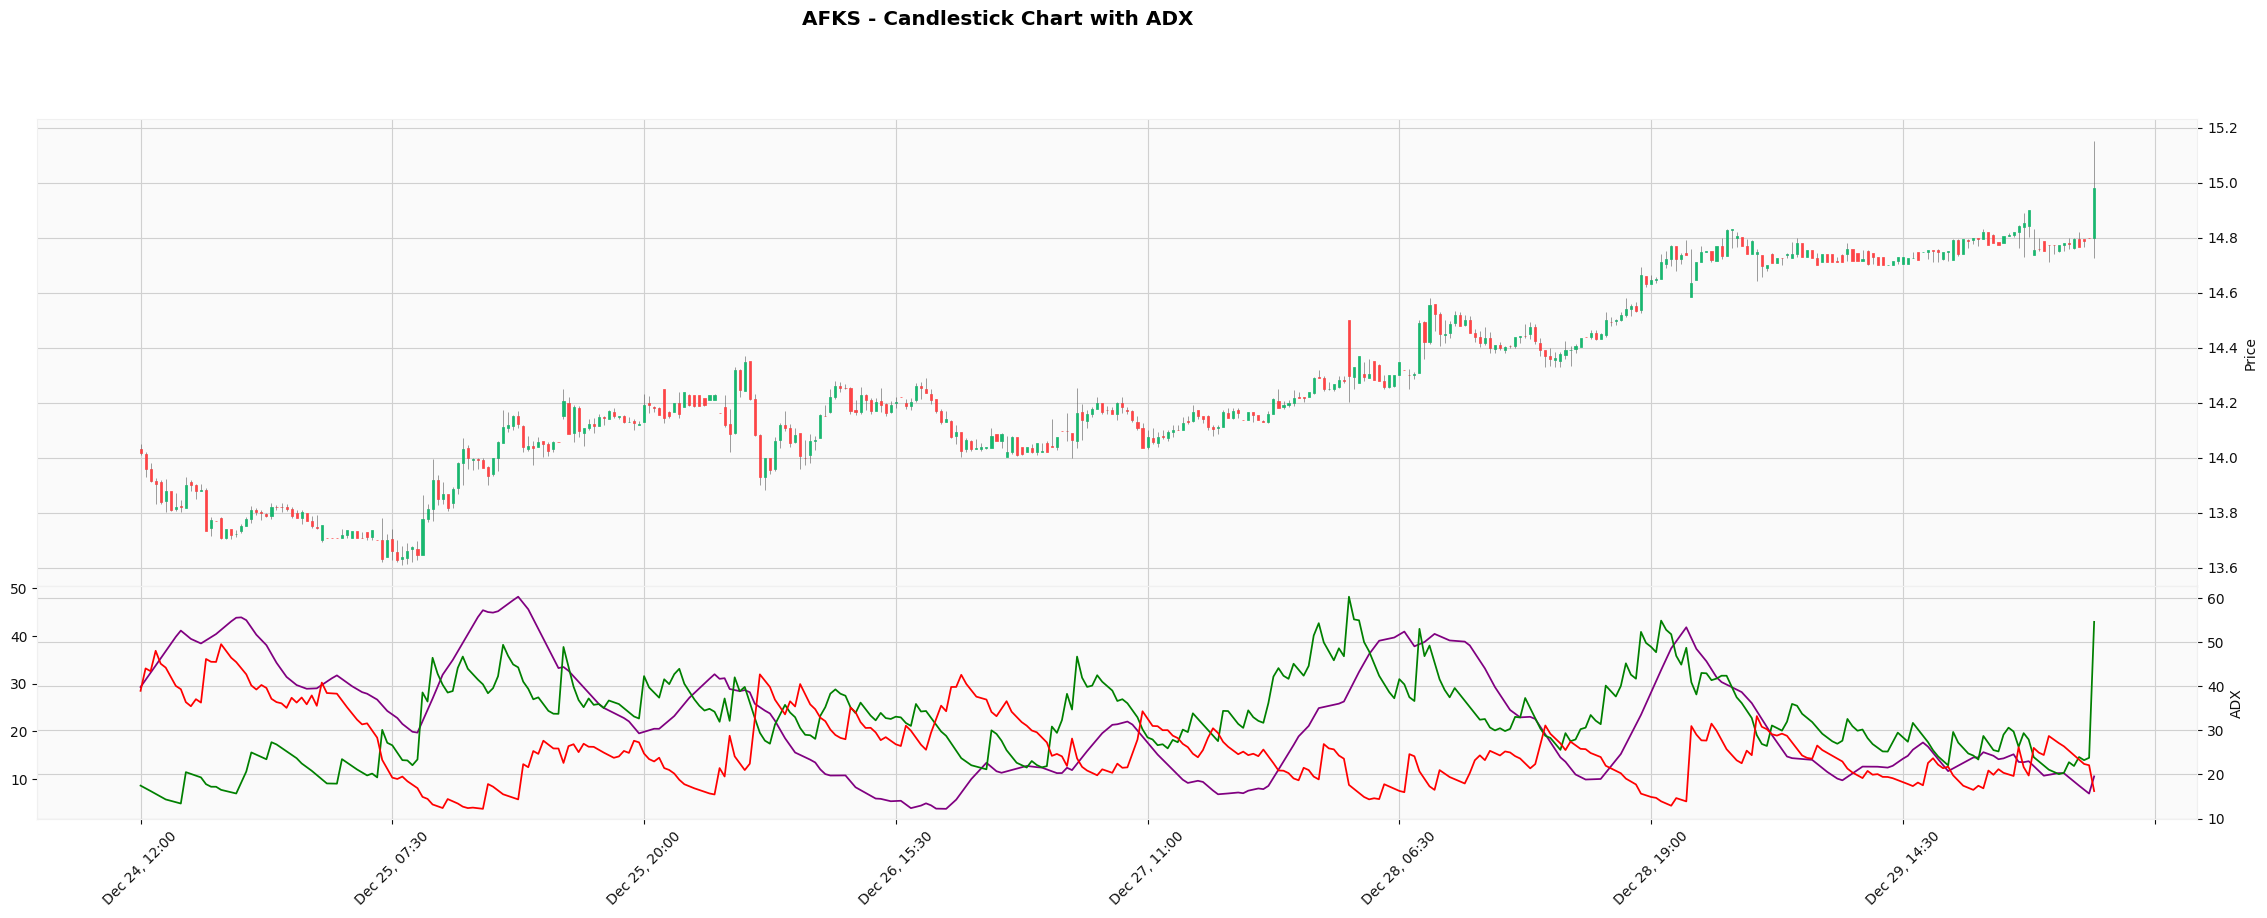

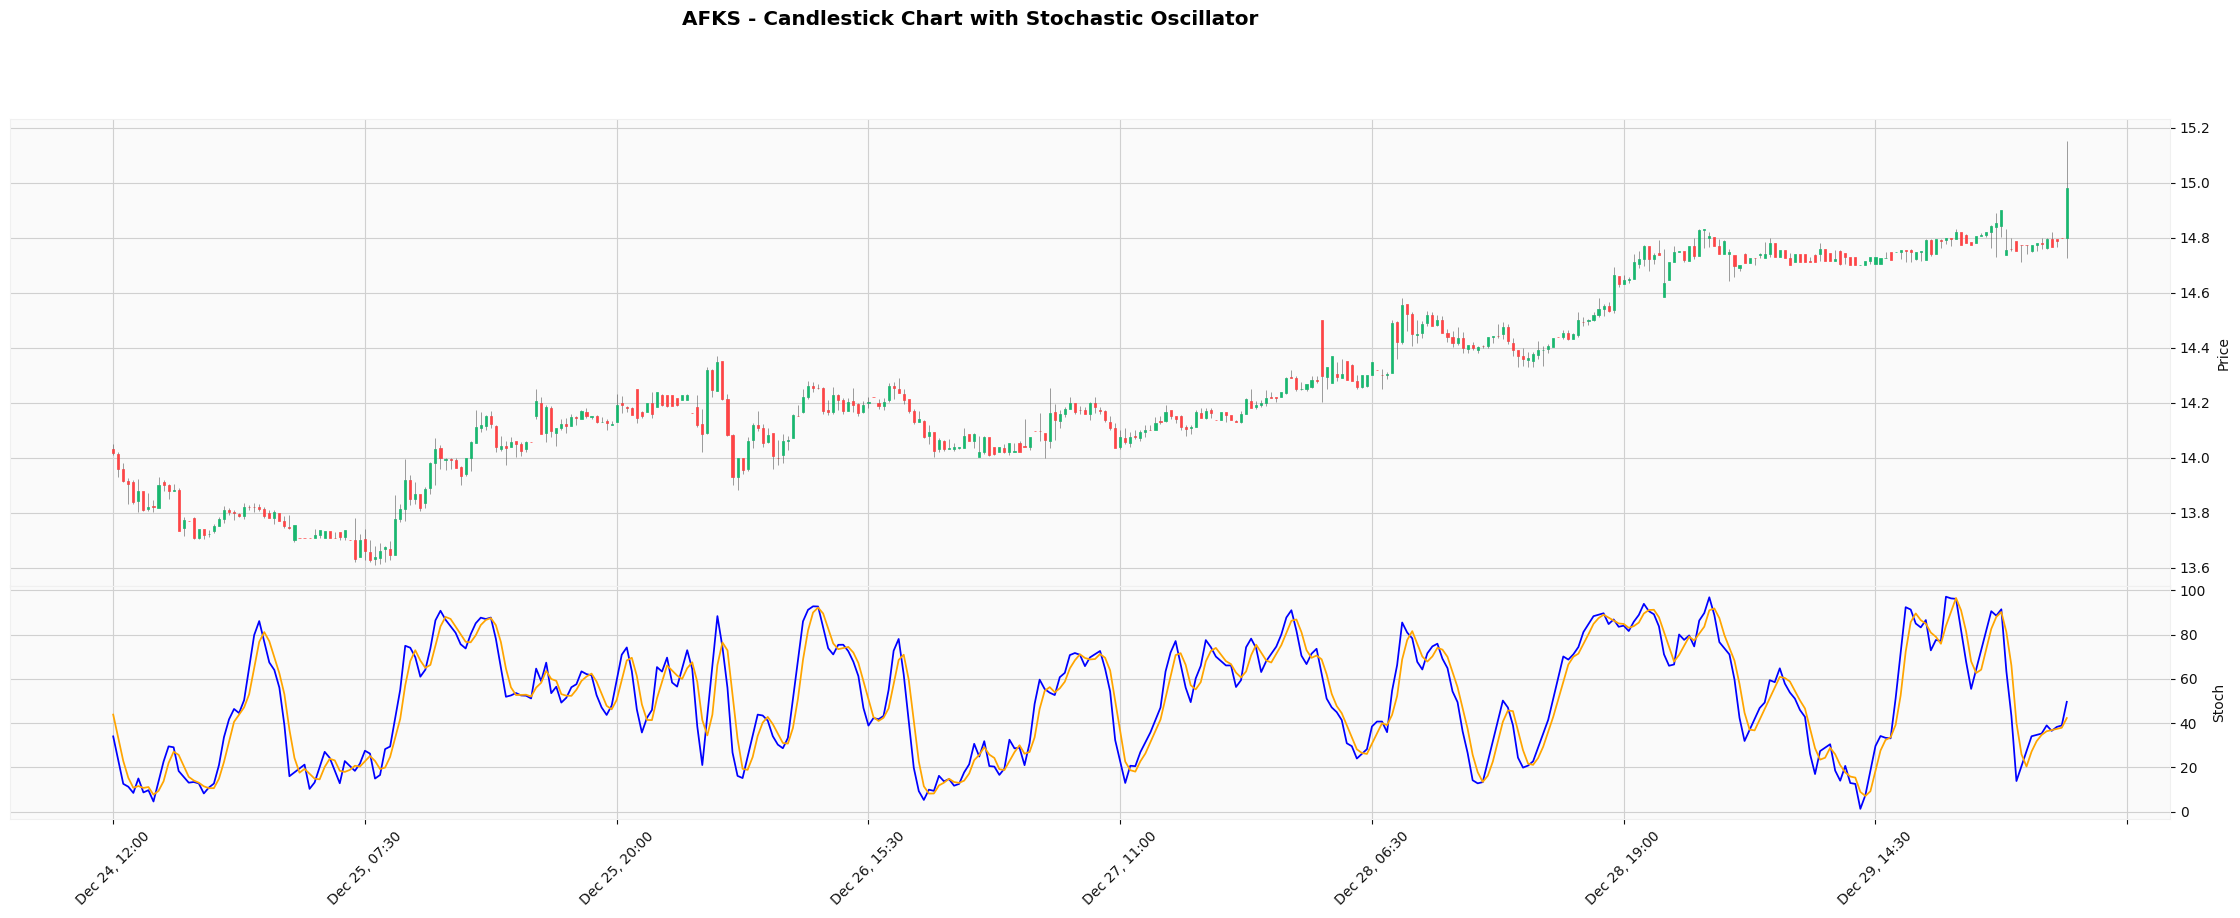

In [4]:
# Select ticker to visualize
ticker = "AFKS"
end_date = pd.Timestamp("2024-12-31T12:00:00Z")
chart_df = df[df['tic'] == ticker]

# The index is already DatetimeIndex, so we can filter directly
filter_date = pd.Timestamp(end_date - timedelta(days=7))
chart_df = chart_df[chart_df.index >= filter_date]

# Create plot addons for different indicators
bb_upper_plot = mpf.make_addplot(chart_df['bb_upper'], color='green', linestyle='dashdot')
bb_lower_plot = mpf.make_addplot(chart_df['bb_lower'], color='red', linestyle='dashdot')
bb_middle_plot = mpf.make_addplot(chart_df['bb_middle'], color='blue')

rsi_plot = mpf.make_addplot(chart_df['rsi'], panel=1, color='purple', ylabel='RSI')

macd_line = mpf.make_addplot(chart_df['macd_line'], panel=2, color='blue', ylabel='MACD')
macd_signal = mpf.make_addplot(chart_df['macd_signal'], panel=2, color='orange')
macd_histogram = mpf.make_addplot(chart_df['macd_histogram'], type='bar', panel=2, 
                                 color=['green' if v >= 0 else 'red' for v in chart_df['macd_histogram']])

sma_12_plot = mpf.make_addplot(chart_df['sma_12'], color='blue', width=1.5)
sma_26_plot = mpf.make_addplot(chart_df['sma_26'], color='orange', width=1.5)
sma_50_plot = mpf.make_addplot(chart_df['sma_50'], color='green', width=1.5)
sma_100_plot = mpf.make_addplot(chart_df['sma_100'], color='red', width=1.5)

# 1. Plot candlestick chart with Bollinger Bands
mpf.plot(chart_df, type='candle', volume=False, 
         title=f"{ticker} - Candlestick Chart with Bollinger Bands",
         style='yahoo', 
         figsize=(30, 10),
         addplot=[bb_upper_plot, bb_middle_plot, bb_lower_plot])

# 2. Plot candlestick chart with RSI
mpf.plot(chart_df, type='candle', volume=False, 
         title=f"{ticker} - Candlestick Chart with RSI",
         style='yahoo', 
         figsize=(30, 10),
         addplot=[rsi_plot])

# 3. Plot candlestick chart with all SMAs
mpf.plot(chart_df, type='candle', volume=True,
         title=f"{ticker} - Candlestick Chart with Moving Averages",
         style='yahoo',
         figsize=(30, 10),
         addplot=[sma_12_plot, sma_26_plot, sma_50_plot, sma_100_plot])

# 4. Plot candlestick chart with MACD
mpf.plot(chart_df, type='candle', volume=True,
         title=f"{ticker} - Candlestick Chart with MACD",
         style='yahoo',
         figsize=(30, 10),
         addplot=[macd_histogram, macd_line, macd_signal],
         panel_ratios=(2, 1))

# Create plots for ADX and Stochastic
adx_plot = mpf.make_addplot(chart_df['adx'], panel=1, color='purple', ylabel='ADX')
adx_pos_plot = mpf.make_addplot(chart_df['adx_positive'], panel=1, color='green')
adx_neg_plot = mpf.make_addplot(chart_df['adx_negative'], panel=1, color='red')

stoch_k_plot = mpf.make_addplot(chart_df['stoch_k'], panel=1, color='blue', ylabel='Stoch')
stoch_d_plot = mpf.make_addplot(chart_df['stoch_d'], panel=1, color='orange')

# 5. Plot candlestick chart with ADX
# ADX > 25 indicates a strong trend (either up or down)
mpf.plot(chart_df, type='candle', volume=False,
         title=f"{ticker} - Candlestick Chart with ADX",
         style='yahoo',
         figsize=(30, 10),
         addplot=[adx_plot, adx_pos_plot, adx_neg_plot],
         panel_ratios=(2, 1))

# 6. Plot candlestick chart with Stochastic Oscillator
# Values over 80 indicate overbought, under 20 indicate oversold
mpf.plot(chart_df, type='candle', volume=False,
         title=f"{ticker} - Candlestick Chart with Stochastic Oscillator",
         style='yahoo',
         figsize=(30, 10),
         addplot=[stoch_k_plot, stoch_d_plot],
         panel_ratios=(2, 1))

## Understanding the Technical Indicators

1. **Bollinger Bands**
   - Three lines: Upper, Middle (20-day SMA), and Lower bands
   - Upper/Lower bands are 2 standard deviations from the middle band
   - Price touching the upper band might indicate overbought conditions
   - Price touching the lower band might indicate oversold conditions

2. **Relative Strength Index (RSI)**
   - Momentum oscillator measuring speed and change of price movements
   - Values range from 0 to 100
   - Above 70 typically indicates overbought conditions
   - Below 30 typically indicates oversold conditions

3. **Moving Averages (SMA)**
   - SMA 12, 26, 50, and 100 periods shown
   - Shorter periods (12, 26) for short-term trends
   - Longer periods (50, 100) for long-term trends
   - Crossovers can signal trend changes

4. **MACD (Moving Average Convergence Divergence)**
   - Blue line: MACD line (12-day EMA minus 26-day EMA)
   - Orange line: Signal line (9-day EMA of MACD)
   - Histogram: Difference between MACD and Signal lines
   - Crossovers and divergences can signal trend changes

5. **ADX (Average Directional Index)**
   - Measures trend strength regardless of direction
   - ADX > 25 indicates a strong trend
   - Green line (+DI) shows uptrend strength
   - Red line (-DI) shows downtrend strength

6. **Stochastic Oscillator**
   - Shows momentum by comparing closing price to price range
   - Blue line (K): Fast stochastic
   - Orange line (D): Slow stochastic
   - Above 80 indicates overbought
   - Below 20 indicates oversold

# Env stage 1: Skeleton with visual play

## Goal: Get the basic OHLCV multi-ticker window working with visual rendering ⏱️ ~3–4h

Tasks:
 1. Build environment scaffolding with Gym-style API: reset, step, render

 2. Load small subset of your OHLCV + indicators data for 3–5 assets

 3. Implement state windowing: e.g., [n_assets, n_timesteps, n_features]

 4. Add deterministic agent: equal weight every step

 5. render() plots: portfolio value over time + asset allocations

Dopamine Hit:
Visualize the portfolio value curve of a dumb agent

Plot the allocations heatmap over time

Save first simulation gif: "env_baseline.gif"

In [23]:
# Read df with index
df = pd.read_csv("./data/data/test_ohlcv_data_15min_indicators.csv", index_col='date')
# Set directory for visualization output
output_dir = "./data/visualizations/test_env"
# Ensure output directory exists
os.makedirs(output_dir, exist_ok=True)

In [24]:
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import numpy as np
from dataclasses import dataclass
from typing import Dict, List, Tuple
import gc

@dataclass
class EnvState:
    """Immutable state container for better memory management"""
    current_step: int
    portfolio_value: float
    weights: np.ndarray
    returns_history: List[float]
    daily_returns: List[float]
    weights_history: List[np.ndarray]

class OptimizedPortfolioEnv(gym.Env):
    """Memory-efficient portfolio management environment with vectorized operations"""
    
    def __init__(self, df, window_size=10, n_assets=None, transaction_cost=0.001, 
                 batch_size=100, use_vectorized=True):
        super().__init__()
        
        self.window_size = window_size
        self.transaction_cost = transaction_cost
        self.batch_size = batch_size
        self.use_vectorized = use_vectorized
        
        # Get unique tickers
        self.tickers = df['tic'].unique()
        self.n_assets = len(self.tickers) if n_assets is None else min(n_assets, len(self.tickers))
        self.tickers = self.tickers[:self.n_assets]
        
        # Define spaces
        self.features = ['open', 'high', 'low', 'close', 'volume', 
                        'rsi', 'macd_line', 'bb_middle']
        self.n_features = len(self.features)

        # Prepare data efficiently
        self._prepare_data(df)

        self.action_space = spaces.Box(low=0, high=1, shape=(self.n_assets,))
        self.observation_space = spaces.Box(
            low=-np.inf, 
            high=np.inf, 
            shape=(self.n_assets, self.window_size, self.n_features)
        )
        
        # Initialize state
        self.state = None
        
    def _prepare_data(self, df: pd.DataFrame) -> None:
        """Prepare data with vectorized operations"""
        # Filter relevant columns only
        features = ['tic', 'open', 'high', 'low', 'close', 'volume', 
                   'rsi', 'macd_line', 'bb_middle']
        df = df[features].copy()
        
        # Convert to structured numpy array for memory efficiency
        data_list = []
        min_length = float('inf')
        
        for ticker in self.tickers:
            ticker_data = df[df['tic'] == ticker].copy()
            min_length = min(min_length, len(ticker_data))
            data_list.append(ticker_data.iloc[:min_length])
        
        # Create 3D array [n_assets, time_steps, features]
        self.data = np.stack([
            df[df['tic'] == ticker][self.features].values[:min_length]
            for ticker in self.tickers
        ])
        
        # Pre-calculate normalization factors
        self.data_mean = np.mean(self.data, axis=1, keepdims=True)
        self.data_std = np.std(self.data, axis=1, keepdims=True) + 1e-8
        
        # Set max steps
        self.max_step = min_length - self.window_size - 1
        
        # Clear memory
        del data_list
        gc.collect()
    
    def _get_observation(self) -> np.ndarray:
        """Get normalized observation window efficiently"""
        if self.use_vectorized:
            # Vectorized operation
            obs = self.data[:, self.state.current_step-self.window_size:self.state.current_step]
            return (obs - self.data_mean) / self.data_std
        else:
            # Traditional operation for comparison
            obs = np.zeros((self.n_assets, self.window_size, self.n_features))
            for i in range(self.n_assets):
                asset_data = self.data[i, self.state.current_step-self.window_size:self.state.current_step]
                mean = np.mean(asset_data, axis=0, keepdims=True)
                std = np.std(asset_data, axis=0, keepdims=True) + 1e-8
                obs[i] = (asset_data - mean) / std
            return obs
    
    def _calculate_returns_vectorized(self) -> Tuple[np.ndarray, float]:
        """Calculate returns using vectorized operations"""
        current_prices = self.data[:, self.state.current_step, self.features.index('close')]
        next_prices = self.data[:, self.state.current_step + 1, self.features.index('close')]
        asset_returns = (next_prices / current_prices) - 1
        portfolio_return = np.sum(self.state.weights * asset_returns)
        return asset_returns, portfolio_return
    
    def reset(self, seed=None):
        """Reset environment state"""
        super().reset(seed=seed)
        
        # Initialize state container
        self.state = EnvState(
            current_step=self.window_size,
            portfolio_value=1.0,
            weights=np.ones(self.n_assets) / self.n_assets,
            returns_history=[1.0],
            daily_returns=[],
            weights_history=[]
        )
        
        return self._get_observation(), {}
    
    def step(self, action):
        """Execute environment step with vectorized operations where possible"""
        if self.state.current_step >= self.max_step:
            return self._get_observation(), 0.0, True, False, {
                'portfolio_value': self.state.portfolio_value,
                'weights': self.state.weights
            }
        
        # Update weights
        new_weights = action / np.sum(action)
        
        # Calculate transaction costs
        if len(self.state.weights_history) > 0:
            transaction_costs = np.sum(np.abs(new_weights - self.state.weights)) * self.transaction_cost
        else:
            transaction_costs = 0
        
        # Calculate returns
        if self.use_vectorized:
            _, portfolio_return = self._calculate_returns_vectorized()
        else:
            current_prices = self.data[:, self.state.current_step, self.features.index('close')]
            next_prices = self.data[:, self.state.current_step + 1, self.features.index('close')]
            asset_returns = (next_prices / current_prices) - 1
            portfolio_return = np.sum(new_weights * asset_returns)
        
        # Apply transaction costs
        portfolio_return -= transaction_costs
        
        # Update state
        self.state = EnvState(
            current_step=self.state.current_step + 1,
            portfolio_value=self.state.portfolio_value * (1 + portfolio_return),
            weights=new_weights,
            returns_history=self.state.returns_history + [self.state.portfolio_value * (1 + portfolio_return)],
            daily_returns=self.state.daily_returns + [portfolio_return],
            weights_history=self.state.weights_history + [new_weights.copy()]
        )
        
        done = self.state.current_step >= self.max_step
        
        return self._get_observation(), portfolio_return, done, False, {
            'portfolio_value': self.state.portfolio_value,
            'weights': self.state.weights,
            'transaction_costs': transaction_costs,
            'returns': portfolio_return
        }
    
    def render(self):
        """Memory-efficient rendering"""
        fig = plt.figure(figsize=(15, 20))
        
        # Use subplot2grid for better layout management
        ax1 = plt.subplot2grid((4, 1), (0, 0))
        ax2 = plt.subplot2grid((4, 1), (1, 0))
        ax3 = plt.subplot2grid((4, 1), (2, 0))
        ax4 = plt.subplot2grid((4, 1), (3, 0))
        
        # Efficient plotting
        ax1.plot(self.state.returns_history, 'b-', label='Portfolio Value')
        ax1.set_title('Portfolio Value Over Time')
        ax1.grid(True)
        ax1.legend()
        
        ax2.plot(self.state.daily_returns, 'g-', label='Daily Returns')
        ax2.axhline(y=0, color='k', linestyle='--', alpha=0.3)
        ax2.set_title('Daily Portfolio Returns')
        ax2.grid(True)
        ax2.legend()
        
        # Use bar container for memory efficiency
        ax3.bar(self.tickers, self.state.weights, color='orange')
        ax3.set_title('Current Portfolio Allocations')
        ax3.grid(True)
        
        if len(self.state.weights_history) > 0:
            weights_array = np.array(self.state.weights_history)
            im = ax4.imshow(weights_array.T, aspect='auto', cmap='YlOrRd')
            ax4.set_yticks(range(len(self.tickers)))
            ax4.set_yticklabels(self.tickers)
            ax4.set_title('Portfolio Weights Over Time')
            plt.colorbar(im, ax=ax4)
        
        plt.tight_layout()
        
        plt.close(fig)
        
        # Clear memory
        gc.collect()

    def cleanup(self):
        """Clean up environment resources"""
        # Clear state
        self.state = None
        
        # Clear data
        self.data = None
        self.data_mean = None
        self.data_std = None
        
        # Force garbage collection
        gc.collect()

# Env stage 2: Basic Reward & Behavior Testing

## Goal: Hook up basic return-based reward and see agent react ⏱️ ~4–5h

Tasks:
 1. Compute simple portfolio return at each step

 2. Agent outputs raw scores → softmax() → allocation weights

 3. Reward = portfolio return – cost term (0.1% turnover penalty)

 4. Log & plot: cumulative return, daily returns, allocations

 5. Add simple greedy agent: picks top-returning asset each step

Dopamine Hit:
See greedy agent outperform equal-weight baseline

Render multiple portfolio value curves for comparison

"reward_test_1.gif" = satisfying animated backtest

# Portfolio Agent Comparison

This section demonstrates the performance comparison between:
1. Equal Weight Agent - baseline strategy
2. Greedy Agent - momentum-based strategy

Features:
- Efficient video rendering with OpenCV
- Interactive HTML5 video playback
- Playback speed control
- Memory-optimized visualization
- Performance metrics tracking

In [25]:
# Imports
import cv2
from IPython.display import HTML, Video
from base64 import b64encode
from io import BytesIO
import time


ModuleNotFoundError: No module named 'cv2'

In [ ]:
def softmax(x):
    """Compute softmax values for each set of scores in x."""
    e_x = np.exp(x - np.max(x))  # Subtract max for numerical stability
    return e_x / e_x.sum()

class GreedyAgent:
    def __init__(self, env, lookback=5):
        self.env = env
        self.lookback = lookback
    
    def get_action(self, observation):
        """Calculate returns for each asset and allocate to the best performer."""
        returns = []
        
        # Get returns for each asset over the lookback period
        for i in range(self.env.n_assets):
            asset_data = observation[i, -self.lookback:, self.env.features.index('close')]
            # Add stability check for division by zero
            if asset_data[0] == 0 or np.isnan(asset_data[0]):
                print(f"Warning: Zero or NaN value encountered for asset {self.env.tickers[i]}")
                returns.append(0.0)
            else:
                asset_return = (asset_data[-1] - asset_data[0]) / (asset_data[0] + 1e-8)
                returns.append(asset_return)
        
        # Convert to scores using softmax
        scores = softmax(np.array(returns))
        return scores


In [26]:
import os
import time
import numpy as np
import pygame
from IPython.display import HTML, display
import base64

def cleanup_visualization_files(output_dir):
    """Clean up any existing visualization files"""
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    else:
        for file in os.listdir(output_dir):
            if file.endswith('.mp4'):
                os.remove(os.path.join(output_dir, file))
                
class InteractiveVisualizer:
    """Create interactive HTML5 video players for visualization"""
    def __init__(self, video_path):
        self.video_path = video_path
        
    def create_player(self):
        """Create an HTML5 video player with controls"""
        video_url = f'data:video/mp4;base64,{self._encode_video()}'
        return HTML(f'''
            <video width="1280" height="720" controls>
                <source src="{video_url}" type="video/mp4">
                Your browser does not support the video tag.
            </video>
        ''')
        
    def _encode_video(self):
        """Encode video file to base64"""
        with open(self.video_path, 'rb') as f:
            return base64.b64encode(f.read()).decode('utf-8')

# Create output directory for visualizations
output_dir = os.path.join(os.path.dirname(os.path.abspath(__file__)), 'viz_output')

NameError: name '__file__' is not defined

In [ ]:
import pygame
import pygame.gfxdraw
from pygame import freetype

class PyGameRenderer:
    """High-performance portfolio visualization using PyGame"""
    
    def __init__(self, width=1500, height=2000, fps=30):
        pygame.init()
        freetype.init()
        
        self.width = width
        self.height = height
        self.fps = fps
        self.screen = None
        self.clock = pygame.time.Clock()
        self.font = freetype.SysFont('Arial', 24)
        self.recording = False
        self.frame_buffer = []
        
        # Colors
        self.BLACK = (0, 0, 0)
        self.WHITE = (255, 255, 255)
        self.BLUE = (0, 0, 255)
        self.GREEN = (0, 255, 0)
        self.RED = (255, 0, 0)
        self.GRAY = (128, 128, 128)
        
        # Layout
        self.margin = 50
        self.plot_height = (height - 5 * self.margin) // 4
        
    def init_display(self, hidden=True):
        """Initialize PyGame display"""
        if hidden:
            os.environ['SDL_VIDEODRIVER'] = 'dummy'
        pygame.display.init()
        self.screen = pygame.display.set_mode((self.width, self.height))
        pygame.display.set_caption('Portfolio Visualization')
        
    def start_recording(self, output_path, fps=30):
        """Start video recording"""
        self.recording = True
        self.output_path = output_path
        self.fps = fps
        self.frame_buffer = []
        
    def stop_recording(self):
        """Stop recording and save video"""
        if not self.frame_buffer:
            return
            
        # Initialize video writer
        h, w = self.frame_buffer[0].shape[:2]
        writer = cv2.VideoWriter(
            self.output_path,
            cv2.VideoWriter_fourcc(*'mp4v'),
            self.fps,
            (w, h)
        )
        
        # Write frames
        for frame in self.frame_buffer:
            writer.write(frame)
            
        writer.release()
        self.frame_buffer = []
        self.recording = False
        
    def render_env(self, env):
        """Render environment state using PyGame"""
        if self.screen is None:
            self.init_display()
            
        # Clear screen
        self.screen.fill(self.WHITE)
        
        # 1. Portfolio Value Plot
        y_start = self.margin
        self.plot_time_series(
            env.state.returns_history,
            'Portfolio Value Over Time',
            y_start,
            color=self.BLUE
        )
        
        # 2. Daily Returns Plot
        y_start = 2 * self.margin + self.plot_height
        self.plot_time_series(
            env.state.daily_returns,
            'Daily Portfolio Returns',
            y_start,
            zero_line=True,
            color=self.GREEN
        )
        
        # 3. Current Allocations Bar Chart
        y_start = 3 * self.margin + 2 * self.plot_height
        self.plot_bar_chart(
            env.tickers,
            env.state.weights,
            'Current Portfolio Allocations',
            y_start
        )
        
        # 4. Weights Heatmap
        if len(env.state.weights_history) > 0:
            y_start = 4 * self.margin + 3 * self.plot_height
            self.plot_heatmap(
                np.array(env.state.weights_history).T,
                env.tickers,
                'Portfolio Weights Over Time',
                y_start
            )
        
        # Update display
        pygame.display.flip()
        
        # Record frame if needed
        if self.recording:
            # Convert PyGame surface to numpy array
            string_image = pygame.image.tostring(self.screen, 'RGB')
            temp_surf = Image.frombytes('RGB', (self.width, self.height), string_image)
            frame = np.array(temp_surf)
            # Convert RGB to BGR for OpenCV
            frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
            self.frame_buffer.append(frame)
        
        return pygame.surfarray.array3d(self.screen)
    
    def plot_time_series(self, data, title, y_start, zero_line=False, color=BLUE):
        """Plot time series data"""
        if not data:
            return
            
        # Calculate plot dimensions
        plot_width = self.width - 2 * self.margin
        x_scale = plot_width / (len(data) - 1) if len(data) > 1 else plot_width
        
        # Calculate y-scale
        y_min, y_max = min(data), max(data)
        if zero_line:
            y_min = min(y_min, 0)
            y_max = max(y_max, 0)
        y_range = y_max - y_min
        y_scale = self.plot_height / (y_range if y_range != 0 else 1)
        
        # Draw title
        self.font.render_to(
            self.screen,
            (self.margin, y_start - 30),
            title,
            self.BLACK
        )
        
        # Draw zero line if needed
        if zero_line:
            zero_y = y_start + self.plot_height // 2
            pygame.draw.line(
                self.screen,
                self.GRAY,
                (self.margin, zero_y),
                (self.width - self.margin, zero_y)
            )
        
        # Draw time series
        points = []
        for i, value in enumerate(data):
            x = self.margin + i * x_scale
            if zero_line:
                y = y_start + self.plot_height // 2 - (value * y_scale)
            else:
                y = y_start + self.plot_height - ((value - y_min) * y_scale)
            points.append((int(x), int(y)))
            
        if len(points) > 1:
            pygame.draw.lines(self.screen, color, False, points, 2)
    
    def plot_bar_chart(self, labels, values, title, y_start):
        """Plot bar chart"""
        # Draw title
        self.font.render_to(
            self.screen,
            (self.margin, y_start - 30),
            title,
            self.BLACK
        )
        
        # Calculate bar dimensions
        n_bars = len(values)
        plot_width = self.width - 2 * self.margin
        bar_width = plot_width / (n_bars * 2)
        x_spacing = plot_width / n_bars
        
        # Draw bars
        for i, (label, value) in enumerate(zip(labels, values)):
            x = self.margin + i * x_spacing
            bar_height = value * self.plot_height
            rect = pygame.Rect(
                x,
                y_start + self.plot_height - bar_height,
                bar_width,
                bar_height
            )
            pygame.draw.rect(self.screen, self.GREEN, rect)
            
            # Draw label
            self.font.render_to(
                self.screen,
                (x, y_start + self.plot_height + 5),
                label,
                self.BLACK
            )
    
    def plot_heatmap(self, data, row_labels, title, y_start):
        """Plot heatmap"""
        # Draw title
        self.font.render_to(
            self.screen,
            (self.margin, y_start - 30),
            title,
            self.BLACK
        )
        
        # Calculate cell dimensions
        n_rows, n_cols = data.shape
        cell_width = (self.width - 2 * self.margin) / n_cols
        cell_height = self.plot_height / n_rows
        
        # Draw heatmap
        for i in range(n_rows):
            for j in range(n_cols):
                value = data[i, j]
                color_value = int(value * 255)
                cell_color = (color_value, 0, 0)
                
                rect = pygame.Rect(
                    self.margin + j * cell_width,
                    y_start + i * cell_height,
                    cell_width,
                    cell_height
                )
                pygame.draw.rect(self.screen, cell_color, rect)
            
            # Draw row label
            self.font.render_to(
                self.screen,
                (self.width - self.margin + 5, y_start + i * cell_height),
                row_labels[i],
                self.BLACK
            )
    
    def cleanup(self):
        """Clean up resources"""
        if self.recording:
            self.stop_recording()
        pygame.quit()

In [ ]:
class PyGameRenderer:
    """High-performance renderer using PyGame"""
    def __init__(self, width=1280, height=720, fps=30):
        pygame.init()
        self.width = width
        self.height = height
        self.fps = fps
        self.screen = pygame.display.set_mode((width, height))
        self.clock = pygame.time.Clock()
        self.font = pygame.font.Font(None, 36)
        self.recording = False
        self.video_writer = None
        
    def start_recording(self, output_path):
        """Start recording video output"""
        self.recording = True
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        self.video_writer = cv2.VideoWriter(
            output_path, fourcc, self.fps, 
            (self.width, self.height)
        )
        
    def render_env(self, env):
        """Render the environment state"""
        # Clear screen
        self.screen.fill((255, 255, 255))
        
        # Get state data
        portfolio_value = env.state.portfolio_value
        returns = env.state.returns_history[-self.width:]
        weights = env.state.weights
        prices = env.state.current_prices
        
        # Draw portfolio value
        value_text = self.font.render(
            f"Portfolio Value: ${portfolio_value:.2f}", 
            True, (0, 0, 0)
        )
        self.screen.blit(value_text, (10, 10))
        
        # Draw returns chart
        if len(returns) > 1:
            self._draw_line_chart(
                returns, 
                (50, 100, self.width-100, 200),
                "Returns History",
                color=(0, 100, 0)
            )
        
        # Draw weights bar chart
        self._draw_bar_chart(
            weights,
            env.tickers,
            (50, 350, self.width-100, 150),
            "Asset Weights"
        )
        
        # Draw price heatmap
        self._draw_heatmap(
            prices.reshape(1, -1),
            env.tickers,
            (50, 550, self.width-100, 50),
            "Asset Prices"
        )
        
        # Update display
        pygame.display.flip()
        self.clock.tick(self.fps)
        
        # Record frame if needed
        if self.recording and self.video_writer is not None:
            # Convert PyGame surface to numpy array
            pixels = pygame.surfarray.array3d(self.screen)
            # Transpose from (width, height, channels) to (height, width, channels)
            pixels = pixels.transpose([1, 0, 2])
            # Convert from RGB to BGR for OpenCV
            pixels = cv2.cvtColor(pixels, cv2.COLOR_RGB2BGR)
            self.video_writer.write(pixels)
        
        return np.array(pygame.surfarray.array3d(self.screen))
    
    def _draw_line_chart(self, data, rect, title, color=(0, 0, 255)):
        """Draw a line chart in the specified rectangle"""
        x, y, w, h = rect
        
        # Draw title
        title_text = self.font.render(title, True, (0, 0, 0))
        self.screen.blit(title_text, (x, y-30))
        
        # Draw axes
        pygame.draw.line(self.screen, (0, 0, 0), (x, y+h), (x+w, y+h))
        pygame.draw.line(self.screen, (0, 0, 0), (x, y), (x, y+h))
        
        # Scale data to fit
        if len(data) > 1:
            min_val = min(data)
            max_val = max(data)
            scale = h / (max_val - min_val) if max_val > min_val else 1
            
            # Draw data points
            points = []
            for i, val in enumerate(data):
                px = x + (i / len(data)) * w
                py = y + h - (val - min_val) * scale
                points.append((int(px), int(py)))
            
            if len(points) > 1:
                pygame.draw.lines(self.screen, color, False, points, 2)
    
    def _draw_bar_chart(self, data, labels, rect, title):
        """Draw a bar chart in the specified rectangle"""
        x, y, w, h = rect
        
        # Draw title
        title_text = self.font.render(title, True, (0, 0, 0))
        self.screen.blit(title_text, (x, y-30))
        
        # Draw bars
        bar_width = w / len(data)
        for i, (val, label) in enumerate(zip(data, labels)):
            bar_height = val * h
            bar_x = x + i * bar_width
            bar_y = y + h - bar_height
            
            pygame.draw.rect(
                self.screen, 
                (0, 0, 255), 
                (bar_x, bar_y, bar_width-2, bar_height)
            )
            
            # Draw label
            label_text = self.font.render(label, True, (0, 0, 0))
            label_text = pygame.transform.rotate(label_text, 45)
            self.screen.blit(
                label_text, 
                (bar_x + bar_width/2 - 10, y + h + 5)
            )
    
    def _draw_heatmap(self, data, labels, rect, title):
        """Draw a heatmap in the specified rectangle"""
        x, y, w, h = rect
        
        # Draw title
        title_text = self.font.render(title, True, (0, 0, 0))
        self.screen.blit(title_text, (x, y-30))
        
        # Normalize data for color mapping
        min_val = np.min(data)
        max_val = np.max(data)
        norm_data = (data - min_val) / (max_val - min_val)
        
        # Draw cells
        cell_width = w / data.shape[1]
        cell_height = h / data.shape[0]
        
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val = norm_data[i, j]
                cell_x = x + j * cell_width
                cell_y = y + i * cell_height
                
                # Create color gradient (blue to red)
                color = (
                    int(255 * val),  # Red
                    0,               # Green
                    int(255 * (1-val)) # Blue
                )
                
                pygame.draw.rect(
                    self.screen,
                    color,
                    (cell_x, cell_y, cell_width-1, cell_height-1)
                )
                
                # Draw value
                value_text = self.font.render(
                    f"${data[i,j]:.2f}", 
                    True, 
                    (255, 255, 255)
                )
                self.screen.blit(
                    value_text,
                    (cell_x + 5, cell_y + cell_height/3)
                )
    
    def cleanup(self):
        """Clean up resources"""
        if self.video_writer is not None:
            self.video_writer.release()
        pygame.quit()

In [27]:
class OptimizedPortfolioEnv(gym.Env):
    """Memory-efficient portfolio environment with PyGame visualization"""
    metadata = {'render_modes': ['human', 'rgb_array'], 'render_fps': 30}
    
    def __init__(self, df, window_size=10, n_assets=None, transaction_cost=0.001,
                 batch_size=100, use_vectorized=True, render_mode='rgb_array'):
        super().__init__()
        
        self.window_size = window_size
        self.transaction_cost = transaction_cost
        self.batch_size = batch_size
        self.use_vectorized = use_vectorized
        self.render_mode = render_mode
        
        # Define features first!
        self.features = ['open', 'high', 'low', 'close', 'volume', 
                        'rsi', 'macd_line', 'bb_middle']
        self.n_features = len(self.features)
        
        # Get unique tickers
        self.tickers = df['tic'].unique()
        self.n_assets = len(self.tickers) if n_assets is None else min(n_assets, len(self.tickers))
        self.tickers = self.tickers[:self.n_assets]
        
        # Prepare data efficiently
        self._prepare_data(df)
        
        # Define spaces
        self.action_space = spaces.Box(low=0, high=1, shape=(self.n_assets,))
        self.observation_space = spaces.Box(
            low=-np.inf, 
            high=np.inf, 
            shape=(self.n_assets, self.window_size, self.n_features)
        )
        
        # Initialize state
        self.state = None
        self.renderer = None
        
    def render(self):
        """Render environment using PyGame"""
        if self.renderer is None:
            self.renderer = PyGameRenderer()
            
        return self.renderer.render_env(self)
    
    def close(self):
        """Clean up resources"""
        if self.renderer is not None:
            self.renderer.cleanup()
            self.renderer = None
        super().close()

# Update run_comparison function to use the new rendering system
def run_comparison(max_steps=1000, render_interval=10):
    """Run and compare agents with PyGame visualization"""
    # Create video renderers
    equal_renderer = PyGameRenderer()
    greedy_renderer = PyGameRenderer()
    
    # Start recording
    equal_renderer.start_recording(os.path.join(output_dir, 'equal_weight.mp4'))
    greedy_renderer.start_recording(os.path.join(output_dir, 'greedy.mp4'))
    
    # Create environments
    env1 = OptimizedPortfolioEnv(df, window_size=10, n_assets=9)
    env2 = OptimizedPortfolioEnv(df, window_size=10, n_assets=9)
    
    # Create agents
    equal_weight = lambda x: np.ones(env1.n_assets) / env1.n_assets
    greedy = GreedyAgent(env2)
    
    # Run episodes
    print("\nRunning equal weight agent...")
    equal_metrics = run_episode(env1, equal_weight, equal_renderer, max_steps, render_interval)
    
    print("\nRunning greedy agent...")
    greedy_metrics = run_episode(env2, greedy, greedy_renderer, max_steps, render_interval)
    
    # Clean up
    env1.close()
    env2.close()
    equal_renderer.cleanup()
    greedy_renderer.cleanup()
    
    return equal_metrics, greedy_metrics

def run_episode(env, agent, renderer, max_steps=1000, render_interval=10):
    """Run single episode with PyGame visualization"""
    observation, _ = env.reset()
    done = False
    steps = 0
    
    print(f"\nEpisode parameters:")
    print(f"Max steps: {max_steps}")
    print(f"Window size: {env.window_size}")
    print(f"Number of assets: {env.n_assets}")
    
    start_time = time.time()
    
    while not done and steps < max_steps:
        steps += 1
        
        # Get action
        if isinstance(agent, GreedyAgent):
            action = agent.get_action(observation)
        else:
            action = agent(observation)
        
        # Execute step
        observation, reward, done, truncated, info = env.step(action)
        
        # Render every N steps
        if steps % render_interval == 0 or done:
            env.render()
        
        if steps % 100 == 0:
            print(f"Step {steps}/{max_steps}")
    
    end_time = time.time()
    print(f"\nEpisode completed in {end_time - start_time:.2f}s")
    print(f"Final portfolio value: ${info['portfolio_value']:.2f}")
    
    return {
        'returns_history': env.state.returns_history,
        'daily_returns': env.state.daily_returns,
        'final_value': info['portfolio_value'],
        'execution_time': end_time - start_time
    }

# Run the comparison with PyGame rendering
print("\nRunning comparison with PyGame rendering...")
equal_metrics, greedy_metrics = run_comparison(max_steps=1000, render_interval=10)

# Create interactive visualizations
equal_viz = InteractiveVisualizer(os.path.join(output_dir, 'equal_weight.mp4'))
greedy_viz = InteractiveVisualizer(os.path.join(output_dir, 'greedy.mp4'))

print("\nEqual Weight Agent Performance:")
display(equal_viz.create_player())

print("\nGreedy Agent Performance:")
display(greedy_viz.create_player())


Running comparison with PyGame rendering...


NameError: name 'PyGameRenderer' is not defined